In [ ]:
# same as ./zzzz/coverage2_increase_feature.ipynb

In [ ]:
# ★config
import os, re, glob

# input_path
data_root = "/home/kmanabe2403/document/dune/superpixel/data_sample"
target_root = os.path.join(data_root, "mag2000")
target_plates = {
    "new": ["pl01", "pl02", "pl04"]
    # "new": ["pl01", "pl02", "pl04", "pl05", "pl06", "pl08", "pl11", "pl13", "pl16", "pl18", "pl19", "pl07", "pl09", "pl10", "pl12", "pl15"],
    # "old": ["pl07", "pl08", "pl11", "pl13", "pl14", "pl15", "pl17", "pl18", "pl19", "pl22", "pl23", "pl24", "pl27"],
}
images_per_plate = 3

# target_plates = {
#     "old": ["pl01", "pl02", "pl04", "pl07", "pl08", "pl09", "pl11", "pl13", "pl14", "pl15", "pl17", "pl18", "pl19", "pl21", "pl22", "pl23", "pl24", "pl27"],
#     "new": ["pl01", "pl02", "pl04", "pl05", "pl06", "pl07", "pl08", "pl09", "pl10", "pl11", "pl12", "pl13", "pl14", "pl15", "pl16", "pl17", "pl18", "pl19"]
# }



# output_path
path_for_data = os.path.join(data_root, "coverage_output_sample")
image_save_dir = os.path.join(path_for_data, "images")
result_dir = os.path.join(path_for_data, "result")
for d in [image_save_dir, result_dir]:
    os.makedirs(d, exist_ok=True)



# load
def natural_sort_key(path):
    filename = os.path.basename(path)
    return [int(text) if text.isdigit() else text.lower() for text in re.split(r'(\d+)', filename)]
image_paths = []
for group, plates in target_plates.items():
    for plate in plates:
        plate_dir = os.path.join(target_root, group, plate)
        paths = sorted(glob.glob(os.path.join(plate_dir, "*.jpg")), key=natural_sort_key)[:images_per_plate]
        for path in paths:
            image_paths.append({"path": path, "group": group, "plate": plate, "name": os.path.splitext(os.path.basename(path))[0]})
print(f"Total images: {len(image_paths)}")
# for i, item in enumerate(image_paths):
    # print(i, item["group"], item["plate"], item["name"])

Total images: 4


In [10]:
# crop & save image.npy
from skimage import io
from skimage.color import rgb2lab
import numpy as np
import gc

crop_params = {"top": 60, "bottom": 100, "left": 60, "right": 100}

def load_and_crop_image(path, crop_params=crop_params):
    img = io.imread(path)
    top, bottom = crop_params["top"], crop_params["bottom"]
    left, right = crop_params["left"], crop_params["right"]
    img = img[top:img.shape[0]-bottom, left:img.shape[1]-right]
    return img

os.makedirs(image_save_dir, exist_ok=True)
for image_id, item in enumerate(image_paths):
    save_path = os.path.join(image_save_dir, f"image_{image_id:04d}.npy")
    image = load_and_crop_image(item["path"])
    np.save(save_path, image)
    # print(f"Image {image_id}: {item['group']}/{item['plate']}/{item['name']} | shape = {image.shape}")
    del image
    gc.collect()

print(f"Saved {len(image_paths)} cropped images to: {image_save_dir}")

Saved 4 cropped images to: /home/kmanabe2403/document/dune/superpixel/data_sample/coverage_output_sample/images


In [ ]:
# pixel-level GMM & save result pic
# input: image.npy
# output: GMM_XXXX_group_plate_name.png, gmm_area_results.csv
# feature6: Gaussian-filtered L (σ=1), Gaussian-filtered L (σ=3), L mean (5×5), L mean (11×11), Brightness mean (5×5), Brightness mean (11×11)

import os, gc, ctypes, psutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from skimage.color import rgb2lab
from scipy.ndimage import uniform_filter, gaussian_filter

output_dir = os.path.join(path_for_data, "result", "coverage_GMM_cluster")
os.makedirs(output_dir, exist_ok=True)

csv_path = os.path.join(output_dir, "gmm_area_results.csv")
image_id_offset = 223

RANDOM_STATE = 0
MAX_PIXELS = 10000
PREDICT_CHUNK = 200000
RAM_WARNING = 5.0
offset = 0

libc = ctypes.CDLL("libc.so.6")

def free_memory():
    gc.collect()
    try:
        libc.malloc_trim(0)
    except:
        pass

def print_memory(msg=""):
    ram = psutil.Process(os.getpid()).memory_info().rss / 1024**3
    print(f"  RAM: {ram:.2f} GB {msg}")
    if ram > RAM_WARNING:
        print(f"  WARNING: RAM > {RAM_WARNING:.1f} GB")
    return ram

def predict_gmm(gmm, feature_arrays, scaler, n_pixels, chunk_size):
    labels = np.empty(n_pixels, dtype=np.int8)
    for start in range(0, n_pixels, chunk_size):
        end = min(start + chunk_size, n_pixels)
        chunk = np.column_stack([x.ravel()[start:end] for x in feature_arrays]).astype(np.float32)
        chunk_scaled = scaler.transform(chunk).astype(np.float32)
        labels[start:end] = gmm.predict(chunk_scaled)
        del chunk, chunk_scaled
    return labels

def get_area_ratios(labels, n_classes):
    counts = np.bincount(labels, minlength=n_classes)
    return counts / len(labels)

processed_ids = set()
if os.path.exists(csv_path):
    try:
        old_df = pd.read_csv(csv_path, usecols=["image_id"])
        processed_ids = set(old_df["image_id"].astype(int))
        del old_df
        print(f"Existing CSV: {len(processed_ids)} images already saved.")
    except Exception:
        pass

for image_id, item in enumerate(image_paths[offset:], start=offset):
    # ---load image & calculate features---

    # if image_id in processed_ids:
    #     print(f"\nImage {image_id}: already processed. Skip.")
    #     continue
    print(f"\nImage {image_id}: {item['group']}/{item['plate']}/{item['name']}")

    image_path = os.path.join(image_save_dir, f"image_{image_id:04d}.npy")
    if not os.path.exists(image_path):
        print(f"File not found: {image_path}")
        continue
    free_memory()

    image = np.load(image_path)
    h, w = image.shape[:2]
    n_pixels = h * w
    print(f"shape = {image.shape}, pixels = {n_pixels:,}")
    # print_memory("after load")

    lab = rgb2lab(image).astype(np.float32)
    L = lab[..., 0] / 100.0
    del lab
    free_memory()

    image_float = image.astype(np.float32)
    if image_float.max() > 1:
        image_float /= 255.0
    brightness = image_float.mean(axis=2).astype(np.float32)
    del image_float
    L_mean_5 = uniform_filter(L, size=5, mode="reflect").astype(np.float32)
    L_mean_11 = uniform_filter(L, size=11, mode="reflect").astype(np.float32)
    brightness_mean_5 = uniform_filter(brightness, size=5, mode="reflect").astype(np.float32)
    brightness_mean_11 = uniform_filter(brightness, size=11, mode="reflect").astype(np.float32)
    gaussian_1 = gaussian_filter(L, sigma=1, mode="reflect").astype(np.float32)
    gaussian_3 = gaussian_filter(L, sigma=3, mode="reflect").astype(np.float32)
    del L
    free_memory()
    # print_memory("after features")


    # ---pixel-sampling---
    feature_arrays = [gaussian_1, gaussian_3, L_mean_5, L_mean_11, brightness_mean_5, brightness_mean_11]
    rng = np.random.default_rng(RANDOM_STATE)
    n_sample = min(MAX_PIXELS, n_pixels)
    sample_idx = rng.choice(n_pixels, n_sample, replace=False)

    features_sample = np.column_stack(
        [x.ravel()[sample_idx] for x in feature_arrays]
    ).astype(np.float32)
    del sample_idx, rng

    scaler = StandardScaler()
    features_scaled = scaler.fit_transform(features_sample).astype(np.float32)
    del features_sample
    free_memory()
    print(f"GMM sample = {n_sample:,}")


    # ---PCA (not used)---
    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    features_pca = pca.fit_transform(features_scaled).astype(np.float32)
    print(f"PCA: PC1={pca.explained_variance_ratio_[0]*100:.1f}%, PC2={pca.explained_variance_ratio_[1]*100:.1f}%")


    # ---plot: original image---
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    axes[0, 0].imshow(image)
    axes[0, 0].set_title("Original")
    axes[0, 0].axis("off")
    csv_rows = []


    # ---GMMlabel 0: class2---
    print("GMMlabel 0: GMM 2...")
    gmm = GaussianMixture(
        n_components=2,
        covariance_type="diag",
        random_state=RANDOM_STATE,
        n_init=1,
        max_iter=100
    )
    gmm.fit(features_scaled)
    sample_labels = gmm.predict(features_scaled)
    labels_0 = predict_gmm(gmm, feature_arrays, scaler, n_pixels, PREDICT_CHUNK)
    fractions_0 = get_area_ratios(labels_0, 2)
    print("  " + " ".join(f"C{k}={fractions_0[k]:.3f}" for k in range(2)))

    axes[0, 1].imshow(image)
    axes[0, 1].imshow(labels_0.reshape(h, w), cmap=ListedColormap(plt.cm.tab10.colors[:2]), alpha=0.35, vmin=0, vmax=1)
    axes[0, 1].set_title("GMMlabel 0: 2 clusters\n" + " ".join(f"C{k}:{fractions_0[k]:.1%}" for k in range(2)))
    axes[0, 1].axis("off")

    for k in range(2):
        csv_rows.append({
            "image_id": image_id + image_id_offset,
            "group": item["group"],
            "plate": item["plate"],
            "name": item["name"],
            "gmm_label": 0,
            "cluster_id": k,
            "area_ratio": fractions_0[k]
        })
    del gmm, sample_labels, labels_0, fractions_0
    free_memory()
    # print_memory("after GMMlabel 0 cleanup")



    # ---GMMlabel 1: class4---
    print("GMMlabel 1: GMM 4...")
    gmm = GaussianMixture(
        n_components=4,
        covariance_type="diag",
        random_state=RANDOM_STATE,
        n_init=1,
        max_iter=100
    )
    gmm.fit(features_scaled)
    sample_labels = gmm.predict(features_scaled)
    labels_1 = predict_gmm(gmm, feature_arrays, scaler, n_pixels, PREDICT_CHUNK)
    fractions_1 = get_area_ratios(labels_1, 4)
    print("  " + " ".join(f"C{k}={fractions_1[k]:.3f}" for k in range(4)))

    axes[1, 0].imshow(image)
    axes[1, 0].imshow(labels_1.reshape(h, w), cmap=ListedColormap(plt.cm.tab10.colors[:4]), alpha=0.35, vmin=0, vmax=3)
    axes[1, 0].set_title("GMMlabel 1: 4 clusters\n" + " ".join(f"C{k}:{fractions_1[k]:.1%}" for k in range(4)))
    axes[1, 0].axis("off")

    for k in range(4):
        csv_rows.append({
            "image_id": image_id + image_id_offset,
            "group": item["group"],
            "plate": item["plate"],
            "name": item["name"],
            "gmm_label": 1,
            "cluster_id": k,
            "area_ratio": fractions_1[k]
        })
    del gmm, sample_labels, labels_1, fractions_1
    free_memory()
    # print_memory("after GMMlabel 1 cleanup")



    # ---GMMlabel 2: class2×2---
    print("GMMlabel 2: hierarchical 2 -> 2...")
    gmm_parent = GaussianMixture(
        n_components=2,
        covariance_type="diag",
        random_state=RANDOM_STATE,
        n_init=1,
        max_iter=100
    )
    gmm_parent.fit(features_scaled)
    sample_parent = gmm_parent.predict(features_scaled)
    labels_parent = predict_gmm(gmm_parent, feature_arrays, scaler, n_pixels, PREDICT_CHUNK)
    final_labels_2 = np.empty(n_pixels, dtype=np.int8)

    for parent_class in [0, 1]:
        print(f"  Sub-GMM parent class {parent_class}...")
        sample_mask = sample_parent == parent_class
        pixel_mask = labels_parent == parent_class
        parent_features = features_scaled[sample_mask]

        if len(parent_features) < 2:
            final_labels_2[pixel_mask] = parent_class * 2
            del sample_mask, pixel_mask, parent_features
            continue

        gmm_sub = GaussianMixture(
            n_components=2,
            covariance_type="diag",
            random_state=RANDOM_STATE,
            n_init=1,
            max_iter=100
        )
        gmm_sub.fit(parent_features)
        pixel_indices = np.flatnonzero(pixel_mask)

        for start in range(0, len(pixel_indices), PREDICT_CHUNK):
            end = min(start + PREDICT_CHUNK, len(pixel_indices))
            idx = pixel_indices[start:end]
            chunk = np.column_stack([x.ravel()[idx] for x in feature_arrays]).astype(np.float32)
            chunk_scaled = scaler.transform(chunk).astype(np.float32)
            sub_labels = gmm_sub.predict(chunk_scaled)
            final_labels_2[idx] = parent_class * 2 + sub_labels
            del idx, chunk, chunk_scaled, sub_labels

        del gmm_sub, sample_mask, pixel_mask, parent_features, pixel_indices
        free_memory()

    fractions_2 = get_area_ratios(final_labels_2, 4)
    print("  " + " ".join(f"C{k}={fractions_2[k]:.3f}" for k in range(4)))

    axes[1, 1].imshow(image)
    axes[1, 1].imshow(final_labels_2.reshape(h, w), cmap=ListedColormap(plt.cm.tab10.colors[:4]), alpha=0.35, vmin=0, vmax=3)
    axes[1, 1].set_title("GMMlabel 2: hierarchical 2 → 2\n" + " ".join(f"C{k}:{fractions_2[k]:.1%}" for k in range(4)))
    axes[1, 1].axis("off")

    for k in range(4):
        csv_rows.append({
            "image_id": image_id + image_id_offset,
            "group": item["group"],
            "plate": item["plate"],
            "name": item["name"],
            "gmm_label": 2,
            "cluster_id": k,
            "area_ratio": fractions_2[k]
        })
    del gmm_parent, sample_parent, labels_parent, final_labels_2, fractions_2
    free_memory()
    # print_memory("after GMMlabel 2 cleanup")



    # save plot
    fig.suptitle(f"{item['group']}/{item['plate']}/{item['name']}", fontsize=14)
    fig.tight_layout()
    save_path = os.path.join(output_dir, f"GMM_{image_id+image_id_offset:04d}_{item['group']}_{item['plate']}_{item['name']}.png")
    fig.savefig(save_path, dpi=120, bbox_inches="tight")
    plt.close(fig)
    del fig, axes



    # save csv
    df_new = pd.DataFrame(csv_rows)
    write_header = not os.path.exists(csv_path)
    df_new.to_csv(csv_path, mode="a", header=write_header, index=False)
    del df_new, csv_rows

    del image
    del brightness
    del gaussian_1, gaussian_3
    del L_mean_5, L_mean_11
    del brightness_mean_5, brightness_mean_11
    del feature_arrays
    del features_scaled, features_pca, pca, scaler
    free_memory()
    # print_memory("after full cleanup")

print("\nFinished.")
print(f"CSV: {csv_path}")


Image 0: new/pl01/20260806_130816
shape = (1376, 1888, 3), pixels = 2,597,888
GMM sample = 10,000
PCA: PC1=98.0%, PC2=1.7%
GMMlabel 0: GMM 2...
  C0=0.607 C1=0.393
GMMlabel 1: GMM 4...
  C0=0.296 C1=0.164 C2=0.233 C3=0.306
GMMlabel 2: hierarchical 2 -> 2...
  Sub-GMM parent class 0...
  Sub-GMM parent class 1...
  C0=0.285 C1=0.323 C2=0.230 C3=0.162

Image 1: new/pl01/20260806_130916
shape = (1376, 1888, 3), pixels = 2,597,888
GMM sample = 10,000
PCA: PC1=96.2%, PC2=3.5%
GMMlabel 0: GMM 2...
  C0=0.652 C1=0.348
GMMlabel 1: GMM 4...
  C0=0.158 C1=0.135 C2=0.615 C3=0.091
GMMlabel 2: hierarchical 2 -> 2...
  Sub-GMM parent class 0...
  Sub-GMM parent class 1...
  C0=0.371 C1=0.280 C2=0.252 C3=0.097

Image 2: new/pl01/20260806_131002
shape = (1376, 1888, 3), pixels = 2,597,888
GMM sample = 10,000
PCA: PC1=97.1%, PC2=2.6%
GMMlabel 0: GMM 2...
  C0=0.457 C1=0.543
GMMlabel 1: GMM 4...
  C0=0.293 C1=0.324 C2=0.171 C3=0.212
GMMlabel 2: hierarchical 2 -> 2...
  Sub-GMM parent class 0...
  Sub-G

In [12]:
# make csv -> manually specify the empty cluster
import os
import pandas as pd

gmm_settings_path = os.path.join(path_for_data, "result", "gmm_settings.csv")

if not os.path.exists(gmm_settings_path):
    rows = [{"imageID": i, "group": item["group"], "plate": item["plate"], "name": item["name"], "GMMlabel": 2, "cluster": "", "fluction": ""} for i, item in enumerate(image_paths)]
    df_settings = pd.DataFrame(rows)
    df_settings.to_csv(gmm_settings_path, index=False, encoding="utf-8-sig")
    print(f"Created: {gmm_settings_path}")
    print(f"Number of images: {len(df_settings)}")
else:
    print(f"Already exists: {gmm_settings_path}")
    print("Existing settings were kept.")

df_settings = pd.read_csv(gmm_settings_path)
print(df_settings.head(10))

Created: /home/kmanabe2403/document/dune/superpixel/data_sample/coverage_output_sample/result/gmm_settings.csv
Number of images: 4
   imageID group plate             name  GMMlabel  cluster  fluction
0        0   new  pl01  20260806_130816         2      NaN       NaN
1        1   new  pl01  20260806_130916         2      NaN       NaN
2        2   new  pl01  20260806_131002         2      NaN       NaN
3        3   new  pl01  20260806_131042         2      NaN       NaN


Photon yield columns: ['group', 'plate', 'photon_yield']
  group plate  photon_yield
0   old  pl01           220
1   old  pl02           135
2   old  pl03             0
3   old  pl04           130
4   old  pl05             0

Processed images: 107
     image_id group plate             name  gmm_label cluster  fluction  \
0           0   new  pl01  20260806_130816        0.0       0       NaN   
1           1   new  pl01  20260806_130916        0.0       0       NaN   
2           2   new  pl01  20260806_131002        2.0     0,2       NaN   
3           4   new  pl01  20260806_131117        0.0       1       NaN   
4           6   new  pl01  20260806_131234        0.0       1       NaN   
..        ...   ...   ...              ...        ...     ...       ...   
102       233   old  pl01              nan        NaN               0.0   
103       234   old  pl02              nan        NaN               0.0   
104       235   old  pl04              nan        NaN               0.0   
10

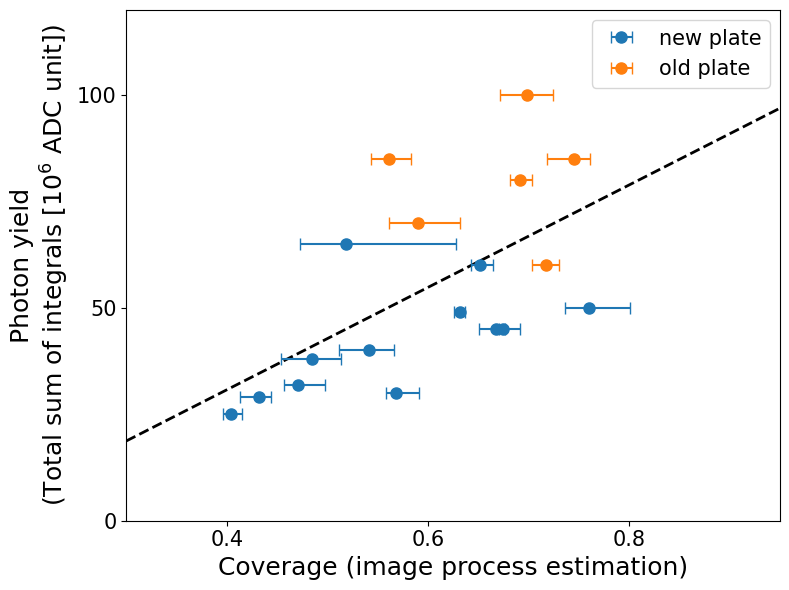


Saved: /home/kmanabe2403/document/dune/superpixel/data/coverage_output_data2/result/coverage_vs_photon_yield.png

===== Linear fit result =====
Slope     = 120.3202
Intercept = -17.3675
R²        = 0.3499
Fit       = y = 120.3202x + -17.3675


In [ ]:
# make plot
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter

# ---settings---
M = 1
result_dir = os.path.join(path_for_data, "result")
gmm_area_path = os.path.join(result_dir, "coverage_GMM_cluster", "gmm_area_results.csv")
gmm_settings_path = os.path.join(result_dir, "gmm_settings.csv")
photon_yield_path = "/home/kmanabe2403/document/dune/superpixel/photon_yield.csv"


# ---load---
df_area = pd.read_csv(gmm_area_path)
df_settings = pd.read_csv(gmm_settings_path)
df_photon = pd.read_csv(photon_yield_path)

df_area.columns = df_area.columns.str.strip()
df_settings.columns = df_settings.columns.str.strip()
df_photon.columns = df_photon.columns.str.strip()

# photon_yield.csv: Type -> group, plate = 1,2,... -> pl01,pl02,...
df_photon = df_photon.rename(columns={"Type": "group"})
df_photon["group"] = df_photon["group"].astype(str).str.strip()
df_photon["plate"] = pd.to_numeric(df_photon["plate"], errors="coerce")
df_photon["plate"] = df_photon["plate"].apply(lambda x: f"pl{int(x):02d}" if pd.notna(x) else np.nan)



def is_valid(x):
    return pd.notna(x) and str(x).strip() != ""
results = []
for _, setting in df_settings.iterrows():
    image_id = int(setting["imageID"])
    group = str(setting["group"]).strip()
    plate = str(setting["plate"]).strip()
    name = str(setting["name"]).strip()
    gmm_label = int(setting["GMMlabel"]) if is_valid(setting["GMMlabel"]) else None

    cluster_ids = []
    if is_valid(setting["cluster"]):
        try:
            cluster_ids = [int(x.strip()) for x in str(setting["cluster"]).split(",") if x.strip()]
        except ValueError:
            print(f"Warning: invalid cluster imageID={image_id}: {setting['cluster']}")
            continue

    fluction = float(setting["fluction"]) if is_valid(setting["fluction"]) else None

    # ---define image coverage---
    if cluster_ids:
        if gmm_label is None:
            print(f"Warning: GMMlabel is empty for imageID={image_id}, cluster={cluster_ids}")
            continue

        match = df_area[
            (df_area["image_id"] == image_id) &
            (df_area["group"] == group) &
            (df_area["plate"] == plate) &
            (df_area["gmm_label"] == gmm_label) &
            (df_area["cluster_id"].isin(cluster_ids))
        ]

        found_clusters = set(match["cluster_id"].astype(int))
        if not set(cluster_ids).issubset(found_clusters):
            print(f"Warning: no match for imageID={image_id}, GMMlabel={gmm_label}, cluster={cluster_ids}")
            continue

        empty_ratio = match["area_ratio"].sum()
        source = "cluster"
        cluster_value = ",".join(map(str, cluster_ids))
        fluction_value = np.nan

    # ---manual mode---
    elif fluction is not None:
        empty_ratio = fluction
        source = "fluction"
        cluster_value = ""
        fluction_value = fluction

    else:
        continue

    coverage = 1.0 - empty_ratio
    results.append({
        "image_id": image_id, "group": group, "plate": plate, "name": name,
        "gmm_label": gmm_label, "cluster": cluster_value, "fluction": fluction_value,
        "empty_ratio": empty_ratio, "coverage": coverage, "source": source
    })

df_result = pd.DataFrame(results)
print(f"\nProcessed images: {len(df_result)}")
print(df_result)



# ---define plate coverage---
plate_results = []
for (group, plate, source), subset in df_result.groupby(["group", "plate", "source"]):
    coverage_values = subset["coverage"].dropna().values
    n = len(coverage_values)
    if n <= M:
        continue
    coverage = np.mean(coverage_values)

    # leave one out of plates
    leave_one_out = np.array([np.mean(np.delete(coverage_values, i)) for i in range(n)])
    coverage_min, coverage_max = leave_one_out.min(), leave_one_out.max()
    plate_results.append({
        "group": group, "plate": plate, "source": source,
        "coverage": coverage, "coverage_min": coverage_min,
        "coverage_max": coverage_max, "n_images": n
    })
df_plate = pd.DataFrame(plate_results)



# ---make plot---
df_plate = df_plate.merge(df_photon[["group", "plate", "photon_yield"]], on=["group", "plate"], how="left")
df_plate = df_plate.dropna(subset=["photon_yield", "coverage"])
print("\nPlate results:")
print(df_plate)

fig, ax = plt.subplots(figsize=(8, 6))
for group, color in [("new", "C0"), ("old", "C1")]:
    for source, marker in [("cluster", "o")]:
        subset = df_plate[(df_plate["group"] == group) & (df_plate["source"] == source)]
        if len(subset) == 0:
            continue

        ax.errorbar(subset["coverage"], subset["photon_yield"],
                    xerr=[subset["coverage"] - subset["coverage_min"],
                          subset["coverage_max"] - subset["coverage"]],
                    fmt=marker, color=color, markersize=8, capsize=4,
                    linestyle="none", label=f"{group} plate", zorder=2)

ax.set_xlabel("Coverage (image process estimation)", fontsize=18)
ax.set_ylabel("Photon yield\n(Total sum of integrals [$10^{6}$ ADC unit])", fontsize=18)
ax.set_xticks(np.arange(0.0, 1.1, 0.2))
ax.xaxis.set_major_formatter(FormatStrFormatter("%.1f"))
ax.set_yticks(np.arange(0, 225, 50))
ax.tick_params(axis="both", labelsize=15)
ax.legend(fontsize=15)
ax.set_xlim(0.3, 0.95)
ax.set_ylim(0, 120)


# ---Linear fit---
x = df_plate["coverage"].values
y = df_plate["photon_yield"].values
coef = np.polyfit(x, y, 1)
fit = np.poly1d(coef)
y_pred = fit(x)

x_fit = np.linspace(*ax.get_xlim(), 100)
ax.plot(x_fit, fit(x_fit), color="black", linestyle="--", linewidth=2, zorder=1,
        label=f"Linear fit: y = {coef[0]:.1f}x + {coef[1]:.1f}")

ss_res = np.sum((y - y_pred) ** 2)
ss_tot = np.sum((y - np.mean(y)) ** 2)
r2 = 1 - ss_res / ss_tot

plt.tight_layout()

plot_path = os.path.join(result_dir, "coverage_vs_photon_yield.png")
plt.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()

print("\n===== Linear fit result =====")
print(f"Slope     = {coef[0]:.4f}")
print(f"Intercept = {coef[1]:.4f}")
print(f"R²        = {r2:.4f}")
print(f"Fit       = y = {coef[0]:.4f}x + {coef[1]:.4f}")
print(f"\nSaved: {plot_path}")


Image 3: new/pl01/20260806_131042
shape = (1376, 1888, 3), pixels = 2,597,888
Number of features = 41
GMM/PCA sample = 20,000
PCA: PC1 = 54.1%, PC2 = 18.1%

PCA loadings:

GMM: 2 clusters
Sample fractions: C0=0.522, C1=0.478
Full fractions:   C0=0.517, C1=0.483


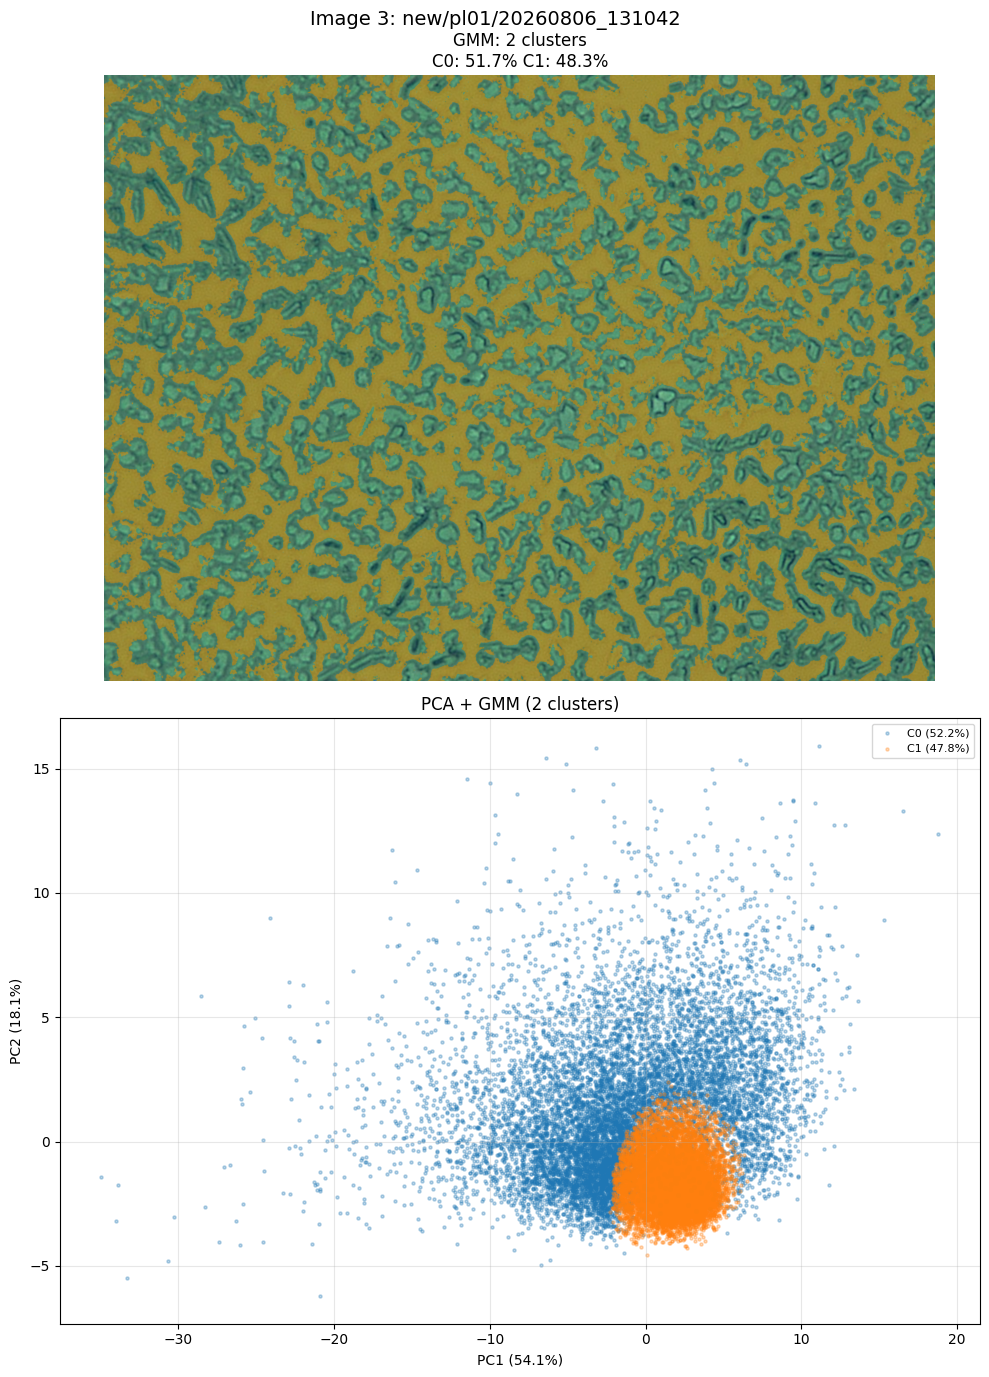

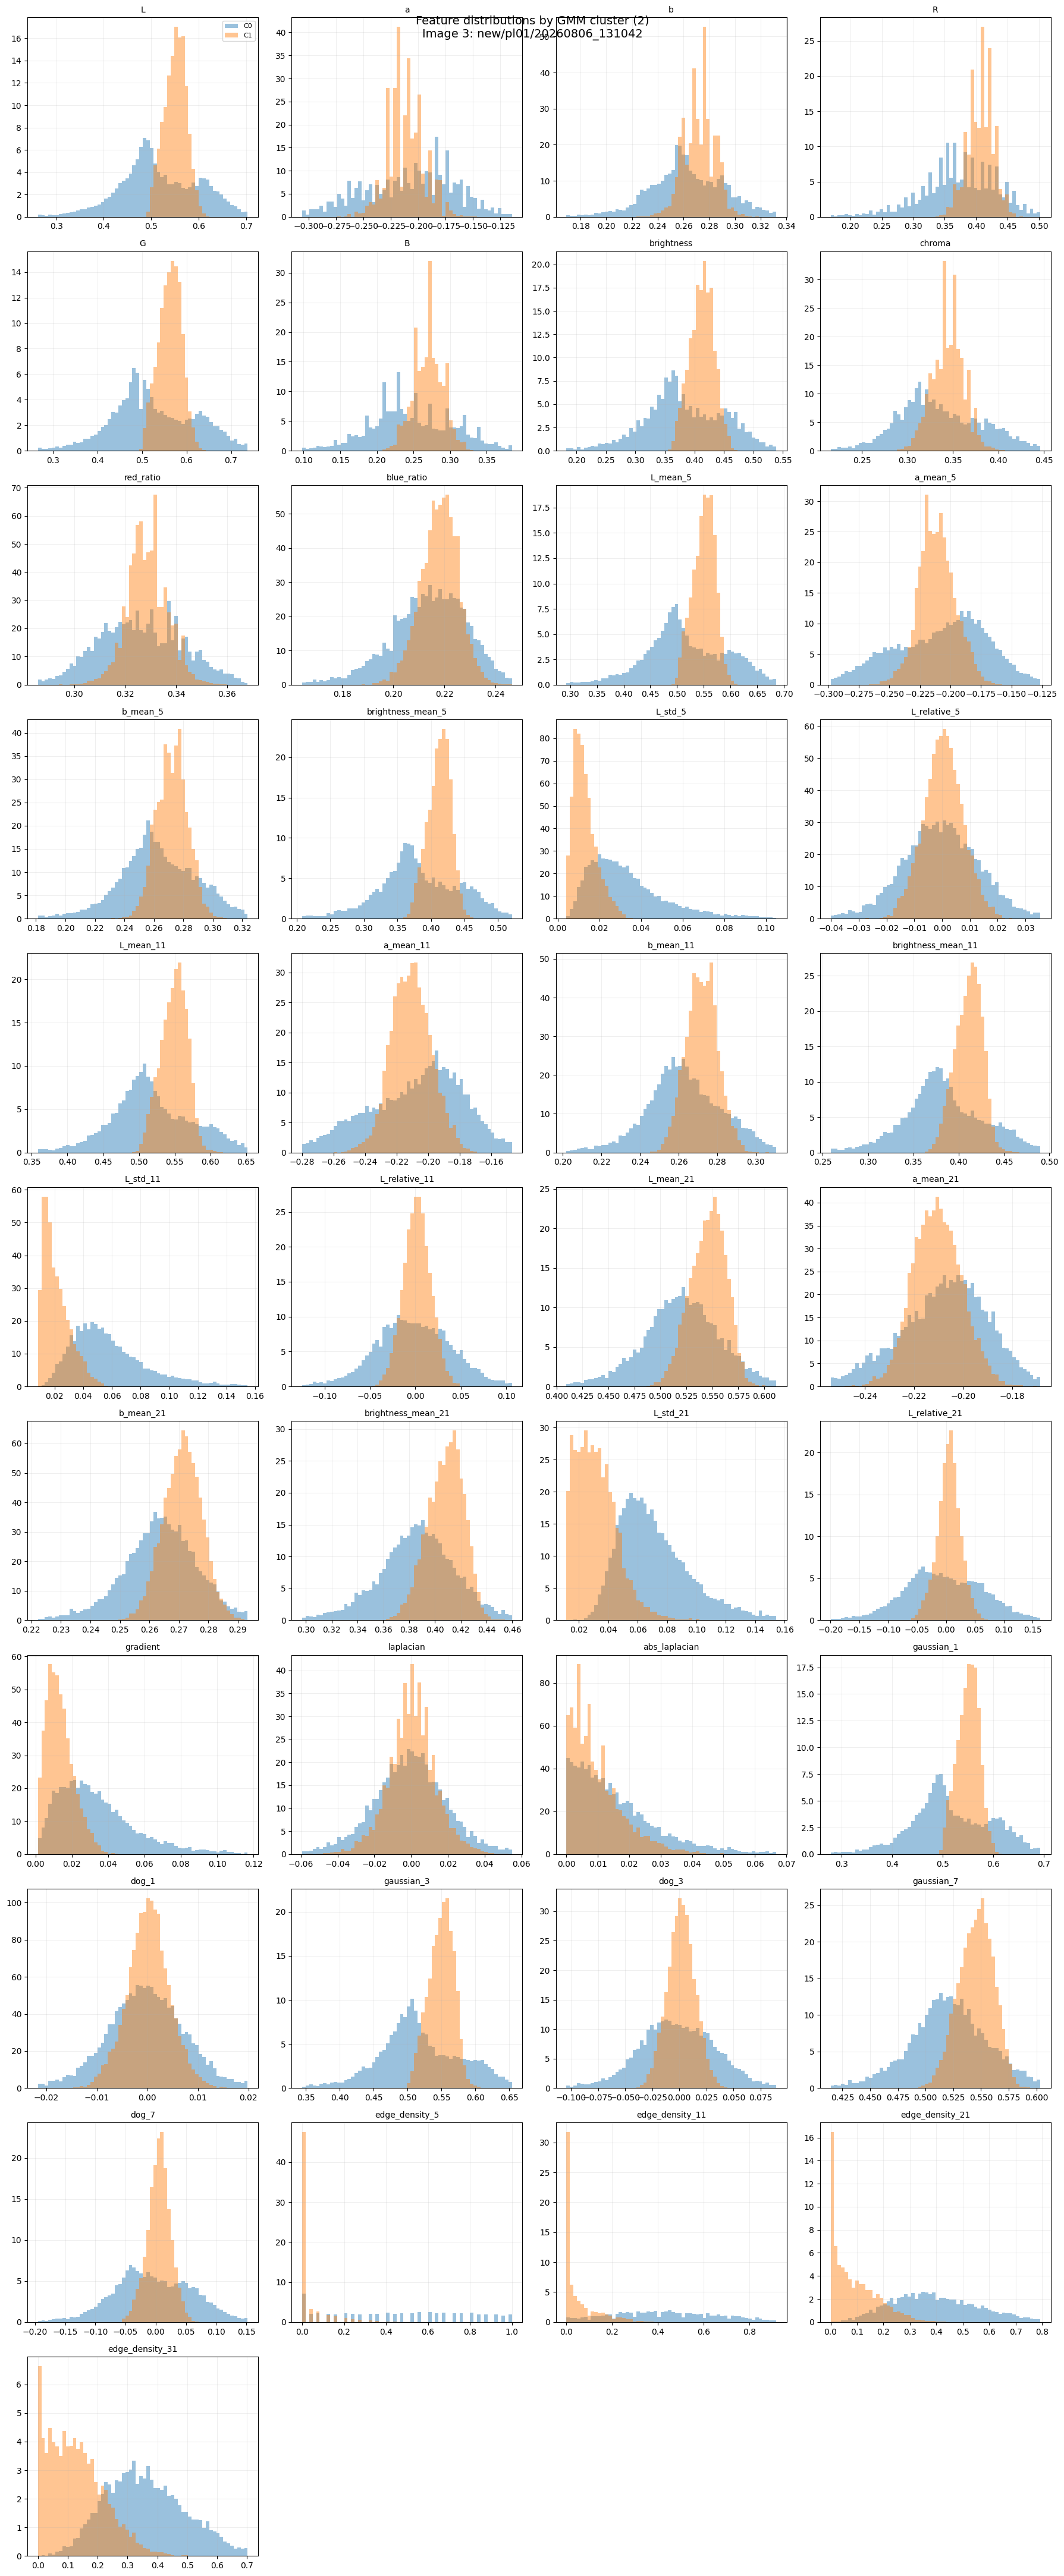


Cluster feature means:

Cluster 0:
  L                        : +0.5149
  a                        : -0.2074
  b                        : +0.2622
  R                        : +0.3717
  G                        : +0.5252
  B                        : +0.2469
  brightness               : +0.3812
  chroma                   : +0.3350
  red_ratio                : +0.3262
  blue_ratio               : +0.2135
  L_mean_5                 : +0.5155
  a_mean_5                 : -0.2075
  b_mean_5                 : +0.2623
  brightness_mean_5        : +0.3818
  L_std_5                  : +0.0339
  L_relative_5             : -0.0006
  L_mean_11                : +0.5172
  a_mean_11                : -0.2077
  b_mean_11                : +0.2626
  brightness_mean_11       : +0.3834
  L_std_11                 : +0.0587
  L_relative_11            : -0.0023
  L_mean_21                : +0.5200
  a_mean_21                : -0.2078
  b_mean_21                : +0.2634
  brightness_mean_21       : +0.3859
  

In [ ]:
# appendix
# feature plot
import os, gc
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from skimage.color import rgb2lab
from skimage.filters import sobel, laplace
from scipy.ndimage import uniform_filter, gaussian_filter

# Settings
IMAGE_IDS = [3]
N_COMPONENTS_LIST = [2]

RANDOM_STATE = 0
MAX_SAMPLE_PIXELS = 20000
PREDICT_CHUNK = 100000
LOCAL_SIZES = [5, 11, 21]
EDGE_THRESHOLD_PERCENTILE = 75
N_BINS = 60

def predict_full_image(gmm, scaler, feature_arrays, n_pixels, chunk_size):
    labels = np.empty(n_pixels, dtype=np.int8)
    for start in range(0, n_pixels, chunk_size):
        end = min(start + chunk_size, n_pixels)
        chunk = np.column_stack([arr.ravel()[start:end] for arr in feature_arrays]).astype(np.float32)
        chunk_scaled = scaler.transform(chunk).astype(np.float32)
        labels[start:end] = gmm.predict(chunk_scaled)
        del chunk, chunk_scaled
    return labels

for image_id in IMAGE_IDS:
    item = image_paths[image_id]
    image_path = os.path.join(image_save_dir, f"image_{image_id:04d}.npy")

    if not os.path.exists(image_path):
        print(f"File not found: {image_path}")
        continue

    print(f"\n{'='*60}")
    print(f"Image {image_id}: {item['group']}/{item['plate']}/{item['name']}")

    image = np.load(image_path)
    h, w = image.shape[:2]
    n_pixels = h * w
    print(f"shape = {image.shape}, pixels = {n_pixels:,}")

    # Color features
    lab = rgb2lab(image)
    L = (lab[..., 0] / 100).astype(np.float32)
    a = (lab[..., 1] / 128).astype(np.float32)
    b = (lab[..., 2] / 128).astype(np.float32)
    del lab

    rgb = image.astype(np.float32)
    if rgb.max() > 1:
        rgb /= 255.0

    R, G, B = rgb[..., 0], rgb[..., 1], rgb[..., 2]
    brightness = (R + G + B) / 3
    chroma = np.sqrt(a * a + b * b)
    red_ratio = R / (R + G + B + 1e-6)
    blue_ratio = B / (R + G + B + 1e-6)
    del rgb

    # Feature maps
    features = {
        "L": L, "a": a, "b": b,
        "R": R, "G": G, "B": B,
        "brightness": brightness,
        "chroma": chroma,
        "red_ratio": red_ratio,
        "blue_ratio": blue_ratio
    }

    for size in LOCAL_SIZES:
        L_mean = uniform_filter(L, size=size, mode="reflect").astype(np.float32)
        a_mean = uniform_filter(a, size=size, mode="reflect").astype(np.float32)
        b_mean = uniform_filter(b, size=size, mode="reflect").astype(np.float32)
        brightness_mean = uniform_filter(brightness, size=size, mode="reflect").astype(np.float32)
        L2_mean = uniform_filter(L * L, size=size, mode="reflect")
        L_std = np.sqrt(np.maximum(L2_mean - L_mean * L_mean, 0)).astype(np.float32)

        features[f"L_mean_{size}"] = L_mean
        features[f"a_mean_{size}"] = a_mean
        features[f"b_mean_{size}"] = b_mean
        features[f"brightness_mean_{size}"] = brightness_mean
        features[f"L_std_{size}"] = L_std
        features[f"L_relative_{size}"] = (L - L_mean).astype(np.float32)
        del L2_mean

    # Gradient and texture
    gradient = sobel(L).astype(np.float32)
    lap = laplace(L).astype(np.float32)

    features["gradient"] = gradient
    features["laplacian"] = lap
    features["abs_laplacian"] = np.abs(lap).astype(np.float32)

    for sigma in [1, 3, 7]:
        smooth = gaussian_filter(L, sigma=sigma, mode="reflect").astype(np.float32)
        features[f"gaussian_{sigma}"] = smooth
        features[f"dog_{sigma}"] = (L - smooth).astype(np.float32)
        del smooth

    # Edge density
    threshold = np.percentile(gradient, EDGE_THRESHOLD_PERCENTILE)
    edge_binary = (gradient > threshold).astype(np.float32)

    for size in [5, 11, 21, 31]:
        features[f"edge_density_{size}"] = uniform_filter(edge_binary, size=size, mode="reflect").astype(np.float32)

    del edge_binary, gradient, lap, L, a, b, R, G, B, brightness, chroma, red_ratio, blue_ratio

    feature_names = list(features.keys())
    feature_arrays = list(features.values())
    n_features = len(feature_names)

    print(f"Number of features = {n_features}")

    # Sample pixels
    rng = np.random.default_rng(RANDOM_STATE)
    n_sample = min(MAX_SAMPLE_PIXELS, n_pixels)
    sample_idx = rng.choice(n_pixels, n_sample, replace=False)

    features_sample = np.column_stack([arr.ravel()[sample_idx] for arr in feature_arrays]).astype(np.float32)

    valid = np.all(np.isfinite(features_sample), axis=1)
    features_sample = features_sample[valid]
    sample_idx = sample_idx[valid]

    print(f"GMM/PCA sample = {len(features_sample):,}")

    # Standardize
    scaler = StandardScaler()
    features_scaled = scaler.fit_transform(features_sample).astype(np.float32)

    # PCA
    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    features_pca = pca.fit_transform(features_scaled).astype(np.float32)

    print(f"PCA: PC1 = {pca.explained_variance_ratio_[0]*100:.1f}%, PC2 = {pca.explained_variance_ratio_[1]*100:.1f}%")

    # PCA loadings
    # print("\nPCA loadings:")
    for pc in range(2):
        order = np.argsort(np.abs(pca.components_[pc]))[::-1]
        # print(f"\nPC{pc + 1}")
        # for i in order:
        #     print(f"  {feature_names[i]:25s} {pca.components_[pc, i]:+.3f}")

    # GMM
    for n_components in N_COMPONENTS_LIST:
        print(f"\nGMM: {n_components} clusters")

        gmm = GaussianMixture(
            n_components=n_components, covariance_type="diag",
            random_state=RANDOM_STATE, n_init=1, max_iter=200, reg_covar=1e-4
        )
        gmm.fit(features_scaled)

        sample_labels = gmm.predict(features_scaled)
        sample_fractions = np.bincount(sample_labels, minlength=n_components) / len(sample_labels)

        pixel_labels = predict_full_image(gmm, scaler, feature_arrays, n_pixels, PREDICT_CHUNK)
        fractions = np.bincount(pixel_labels, minlength=n_components) / n_pixels

        print("Sample fractions:", ", ".join(f"C{k}={sample_fractions[k]:.3f}" for k in range(n_components)))
        print("Full fractions:  ", ", ".join(f"C{k}={fractions[k]:.3f}" for k in range(n_components)))

        label_image = pixel_labels.reshape(h, w)

        # Original image + GMM overlay + PCA
        fig, axes = plt.subplots(2, 1, figsize=(10, 14))

        axes[0].imshow(image)
        overlay = np.zeros((h, w, 4), dtype=np.float32)

        for k in range(n_components):
            mask = label_image == k
            rgba = plt.cm.tab10(k)
            overlay[mask, :3] = rgba[:3]
            overlay[mask, 3] = 0.35

        axes[0].imshow(overlay)
        axes[0].set_title(f"GMM: {n_components} clusters\n" +
                          " ".join(f"C{k}: {fractions[k]*100:.1f}%" for k in range(n_components)))
        axes[0].axis("off")

        for k in range(n_components):
            mask = sample_labels == k
            axes[1].scatter(features_pca[mask, 0], features_pca[mask, 1],
                            s=5, alpha=0.3, label=f"C{k} ({sample_fractions[k]*100:.1f}%)")

        axes[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
        axes[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
        axes[1].set_title(f"PCA + GMM ({n_components} clusters)")
        axes[1].legend(fontsize=8)
        axes[1].grid(alpha=0.3)

        fig.suptitle(f"Image {image_id}: {item['group']}/{item['plate']}/{item['name']}", fontsize=14)
        plt.tight_layout()
        plt.show()
        plt.close(fig)

        # Feature histograms
        n_cols = 4
        n_rows = int(np.ceil(n_features / n_cols))
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4*n_rows))
        axes = np.asarray(axes).reshape(-1)

        for i, feature_name in enumerate(feature_names):
            ax = axes[i]
            values = features_sample[:, i]
            xmin, xmax = np.percentile(values, [0.5, 99.5])

            if xmax <= xmin:
                xmin, xmax = values.min(), values.max() + 1e-6

            bins = np.linspace(xmin, xmax, N_BINS + 1)

            for k in range(n_components):
                mask = sample_labels == k
                if np.any(mask):
                    ax.hist(values[mask], bins=bins, density=True, alpha=0.45,
                            color=plt.cm.tab10(k), label=f"C{k}")

            ax.set_title(feature_name, fontsize=10)
            ax.grid(alpha=0.2)

            if i == 0:
                ax.legend(fontsize=8)

        for i in range(n_features, len(axes)):
            axes[i].axis("off")

        fig.suptitle(f"Feature distributions by GMM cluster ({n_components})\n"
                     f"Image {image_id}: {item['group']}/{item['plate']}/{item['name']}", fontsize=14)
        plt.tight_layout()
        plt.show()
        plt.close(fig)

        # Cluster-wise feature means
        print("\nCluster feature means:")
        for k in range(n_components):
            mask = sample_labels == k
            means = features_sample[mask].mean(axis=0)

            print(f"\nCluster {k}:")
            for name, value in zip(feature_names, means):
                print(f"  {name:25s}: {value:+.4f}")

        del gmm, sample_labels, pixel_labels, label_image, overlay
        gc.collect()

    del image, features, feature_arrays, sample_idx
    del scaler, pca, features_sample, features_scaled, features_pca
    gc.collect()

print("\nFinished.")


Image 3: new/pl01/20260806_131042
shape = (1376, 1888, 3), pixels = 2,597,888
GMM sample = 10,000
PCA: PC1=96.6%, PC2=3.0%
  Fit GMM 2... done | C0=0.297, C1=0.703
  Fit GMM 3... done | C0=0.213, C1=0.414, C2=0.373
  Fit GMM 4... done | C0=0.172, C1=0.380, C2=0.315, C3=0.133


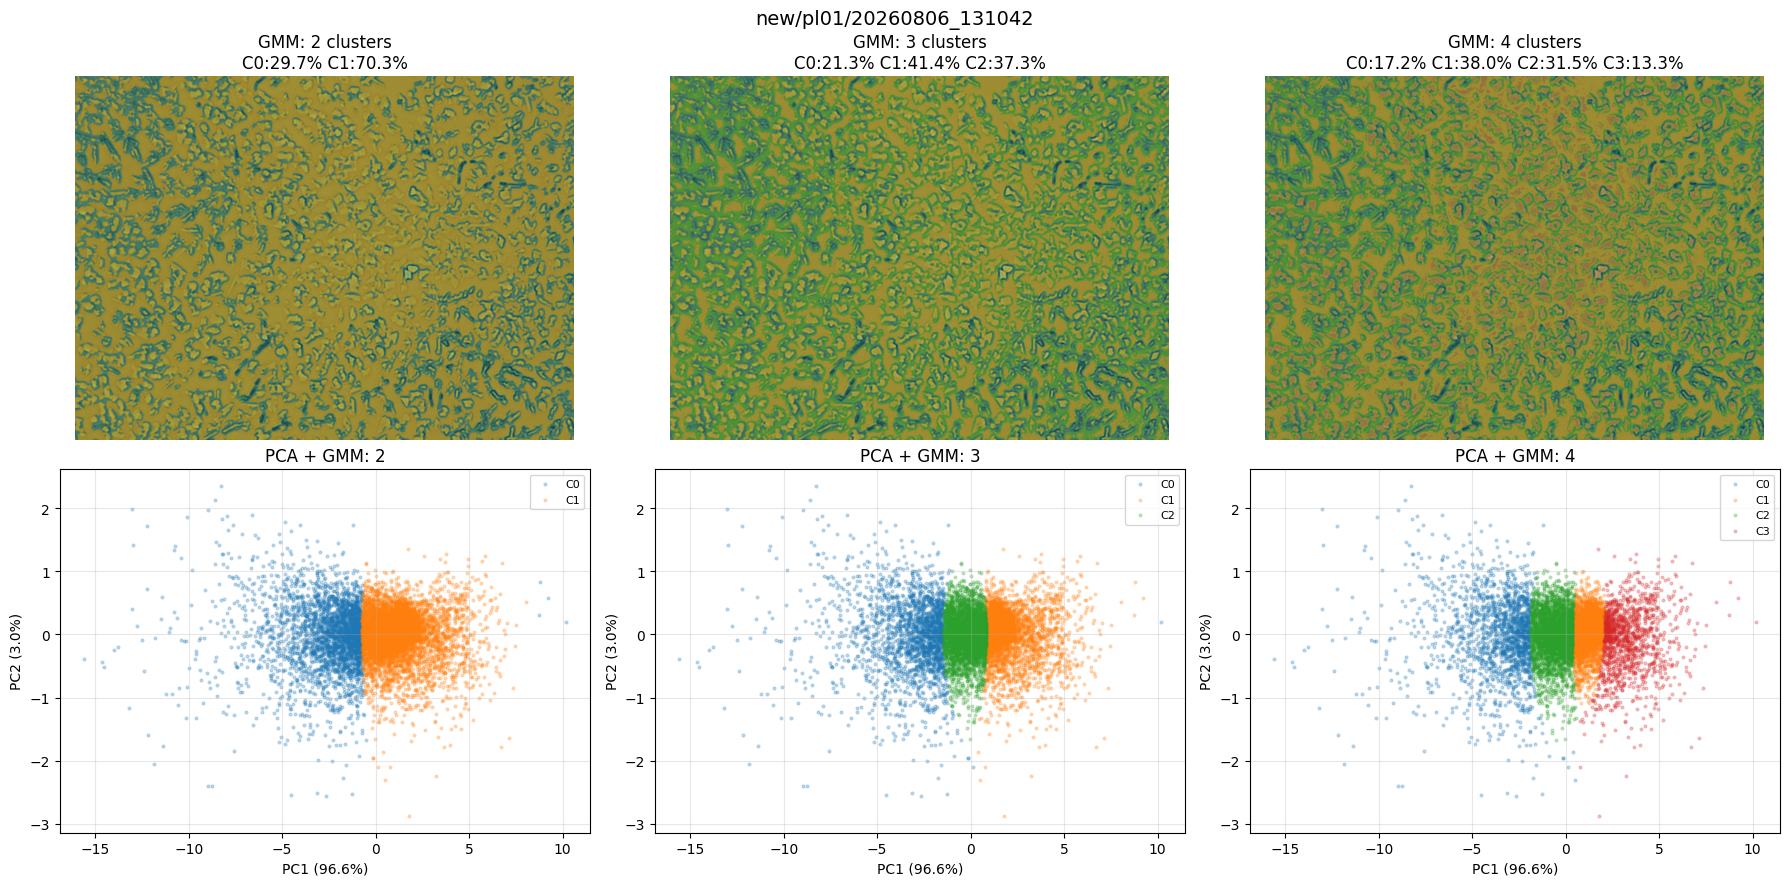


Image 4: new/pl01/20260806_131117
shape = (1376, 1888, 3), pixels = 2,597,888
GMM sample = 10,000
PCA: PC1=97.5%, PC2=2.3%
  Fit GMM 2... done | C0=0.428, C1=0.572
  Fit GMM 3... done | C0=0.191, C1=0.527, C2=0.282
  Fit GMM 4... done | C0=0.116, C1=0.490, C2=0.176, C3=0.217


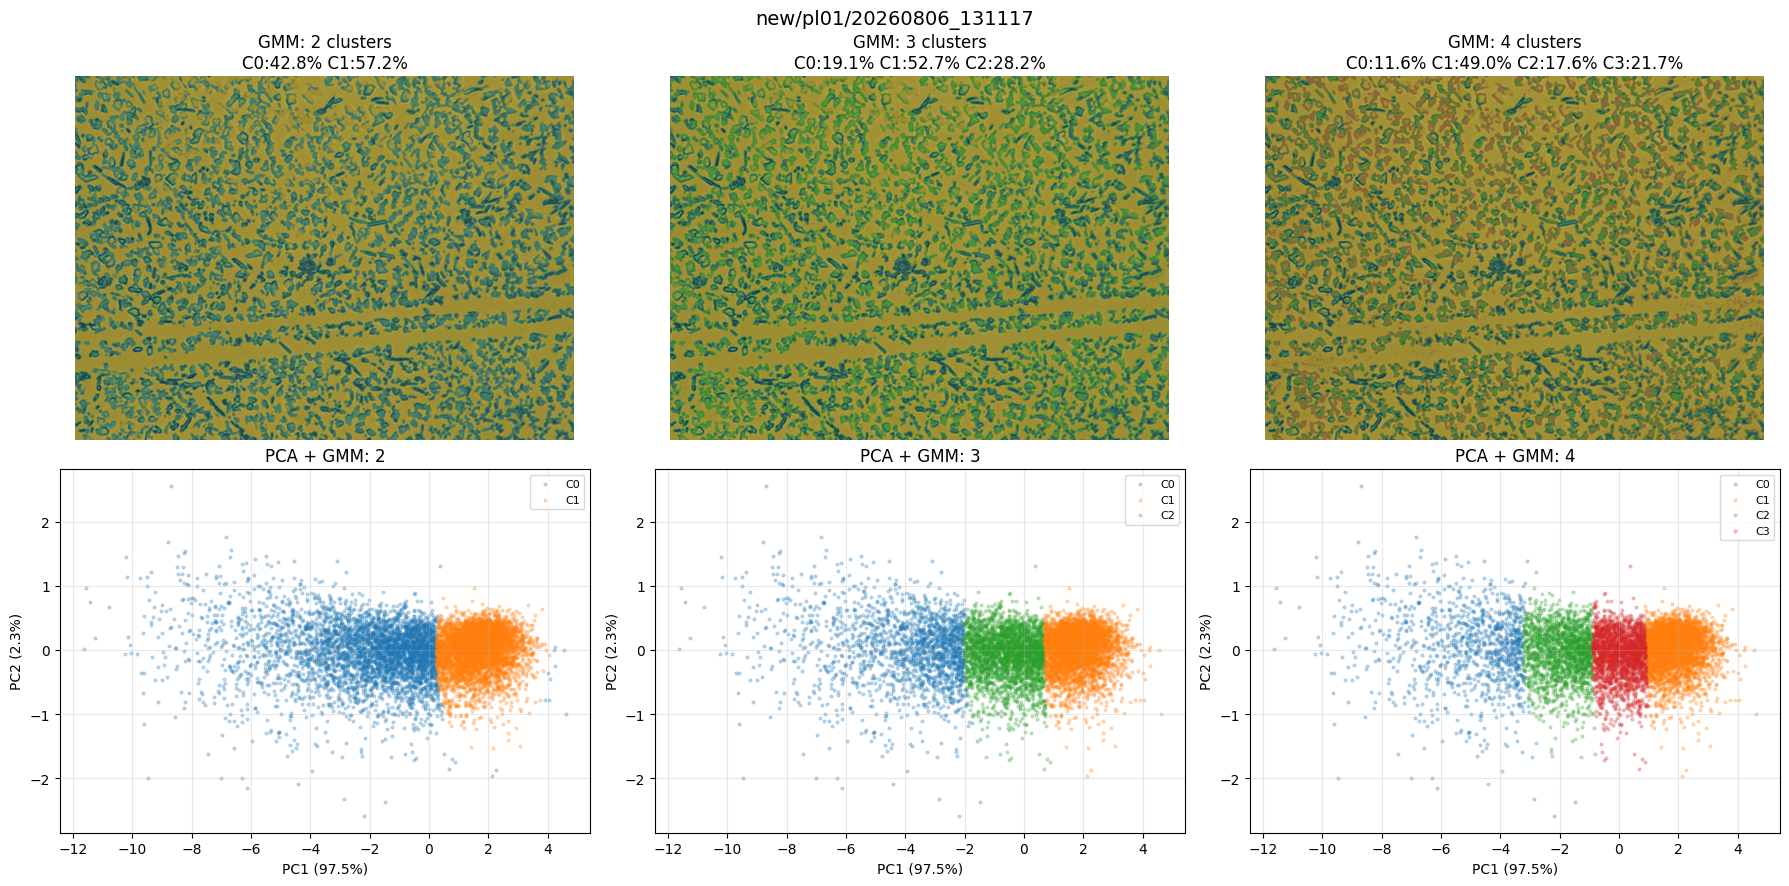


Finished.


In [ ]:
# appendix
# GMM class 2,3,4
import os, gc, ctypes, psutil
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from skimage.color import rgb2lab
from scipy.ndimage import uniform_filter, gaussian_filter

RANDOM_STATE = 0
MAX_PIXELS = 10000
PREDICT_CHUNK = 200000
N_COMPONENTS_LIST = [2, 3, 4]
imageid_start = 3
imageid_end = 5

libc = ctypes.CDLL("libc.so.6")

def free_memory():
    gc.collect()
    try: libc.malloc_trim(0)
    except: pass

for image_id in range(imageid_start, imageid_end+1):
    item = image_paths[image_id]
    print(f"\nImage {image_id}: {item['group']}/{item['plate']}/{item['name']}")

    image_path = os.path.join(image_save_dir, f"image_{image_id:04d}.npy")
    if not os.path.exists(image_path):
        print(f"File not found: {image_path}")
        continue

    free_memory()
    image = np.load(image_path)
    h, w = image.shape[:2]
    n_pixels = h * w
    print(f"shape = {image.shape}, pixels = {n_pixels:,}")

    # Features
    lab = rgb2lab(image).astype(np.float32)
    L = lab[..., 0] / 100.0
    del lab

    image_float = image.astype(np.float32)
    if image_float.max() > 1: image_float /= 255.0
    brightness = image_float.mean(axis=2).astype(np.float32)
    del image_float

    L_mean_5 = uniform_filter(L, size=5, mode="reflect").astype(np.float32)
    L_mean_11 = uniform_filter(L, size=11, mode="reflect").astype(np.float32)
    brightness_mean_5 = uniform_filter(brightness, size=5, mode="reflect").astype(np.float32)
    brightness_mean_11 = uniform_filter(brightness, size=11, mode="reflect").astype(np.float32)
    gaussian_1 = gaussian_filter(L, sigma=1, mode="reflect").astype(np.float32)
    gaussian_3 = gaussian_filter(L, sigma=3, mode="reflect").astype(np.float32)
    del L

    feature_arrays = [gaussian_1, gaussian_3, L_mean_5, L_mean_11, brightness_mean_5, brightness_mean_11]

    # Random sample
    rng = np.random.default_rng(RANDOM_STATE)
    n_sample = min(MAX_PIXELS, n_pixels)
    sample_idx = rng.choice(n_pixels, n_sample, replace=False)
    features_sample = np.column_stack([x.ravel()[sample_idx] for x in feature_arrays]).astype(np.float32)
    del sample_idx, rng

    scaler = StandardScaler()
    features_scaled = scaler.fit_transform(features_sample).astype(np.float32)
    del features_sample

    print(f"GMM sample = {n_sample:,}")

    # PCA
    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    features_pca = pca.fit_transform(features_scaled).astype(np.float32)
    print(f"PCA: PC1={pca.explained_variance_ratio_[0]*100:.1f}%, PC2={pca.explained_variance_ratio_[1]*100:.1f}%")

    fig, axes = plt.subplots(2, 3, figsize=(18, 9))

    for col, n_components in enumerate(N_COMPONENTS_LIST):
        print(f"  Fit GMM {n_components}...", end=" ", flush=True)

        gmm = GaussianMixture(n_components=n_components, covariance_type="diag", random_state=RANDOM_STATE, n_init=1, max_iter=100)
        gmm.fit(features_scaled)
        sample_labels = gmm.predict(features_scaled)

        pixel_labels = np.empty(n_pixels, dtype=np.int8)

        for start in range(0, n_pixels, PREDICT_CHUNK):
            end = min(start + PREDICT_CHUNK, n_pixels)
            chunk = np.column_stack([x.ravel()[start:end] for x in feature_arrays]).astype(np.float32)
            chunk_scaled = scaler.transform(chunk).astype(np.float32)
            pixel_labels[start:end] = gmm.predict(chunk_scaled)
            del chunk, chunk_scaled

        fractions = np.bincount(pixel_labels, minlength=n_components) / n_pixels
        print("done | " + ", ".join(f"C{k}={fractions[k]:.3f}" for k in range(n_components)))

        # GMM image
        ax = axes[0, col]
        ax.imshow(image)
        ax.imshow(pixel_labels.reshape(h, w), cmap=ListedColormap(plt.cm.tab10.colors[:n_components]), alpha=0.35, vmin=0, vmax=n_components-1)
        ax.set_title(f"GMM: {n_components} clusters\n" + " ".join(f"C{k}:{fractions[k]:.1%}" for k in range(n_components)))
        ax.axis("off")

        # PCA
        ax = axes[1, col]
        for k in range(n_components):
            mask = sample_labels == k
            ax.scatter(features_pca[mask, 0], features_pca[mask, 1], s=4, alpha=0.25, label=f"C{k}")

        ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
        ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
        ax.set_title(f"PCA + GMM: {n_components}")
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3)

        del gmm, sample_labels, pixel_labels, fractions, mask
        free_memory()

    fig.suptitle(f"{item['group']}/{item['plate']}/{item['name']}", fontsize=14)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

    del fig, axes, pca, features_pca, features_scaled, scaler
    del feature_arrays, gaussian_1, gaussian_3, L_mean_5, L_mean_11
    del brightness_mean_5, brightness_mean_11, brightness, image
    free_memory()

print("\nFinished.")